# Circuit and dose dial at Gemma's BFS-vs-DFS fork: a runnable demo of `method.py`

**Artifact** `art_HY7uYZz-OjRW` (iteration 7) · **model** `google/gemma-3-4b-it` (bf16) · **task T1**: *write `solve(grid, start, goal)` that returns a path between two cells of a grid.*

**The question.** Ask Gemma for a grid path-finder and it does not always design the same algorithm. Every program opens with the same 32 tokens c* (```` ```python ````, `def solve(grid, start, goal):`, `rows = len(grid)`, `cols = len(grid[0])`, indent). Response token 32 then decides:
` visited` leads to depth-first search (DFS), while a blank line, `if`, `queue` or `q` lead to breadth-first search (BFS). The artifact asks three questions at that fork:

- **G1:** which heads and MLPs compute the fork margin m = logsumexp(z[B]) − z['visited']?
- **G2:** is a low-rank DAS subspace at the fork a *dose dial* that adds **correct** BFS programs?
- **G3:** does the fork margin alone predict what temperature does? In other words, is temperature really the "creativity knob"?

**What `method.py` is.** It is the pipeline's stage dispatcher (`--stage s0 | engine | label | g3a | … | outputs`). It holds the S0 CPU tests, the GPU *engine* stage (unit tests, the engine check, U6 and G3-cal), the *label* stage and `main()`. The other stages live in `src/`.

**What this notebook runs.** A Colab CPU cannot sample Gemma-3-4B in minutes, so the demo splits `method.py` into two parts:

| Part | How |
|---|---|
| S0 tests: labeller on the 12 reference programs, hidden-test checker vs 5 mutants, CRN streams, the DAS toy, instrument listing, hash-chained **commit #0** | **run live** with the original code |
| Label worker over the **50 programs Gemma wrote** in the engine check (frozen runtime + AST labeller, hidden tests), the engine-check decision rule, the fork-token analysis | **run live** with the original code |
| GPU steps: sampling Gemma, the GPU unit tests U1-U4, the batch-shape time test | original code shown in markdown; their **recorded outputs** are replayed from `mini_demo_data.json` |
| Headline results of the other GPU stages (G3 temperature law, G2 dose dial, F4 geometry in actual activation coordinates) | plotted from the **recorded** results at the end |

Everything the code needs (the 50 generations, the artifact's helper modules, the frozen labeller suite and the recorded results) travels in one file, `mini_demo_data.json`.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab (the artifact logs with it), always install
_pip('loguru==0.7.3')

# numpy, matplotlib, huggingface_hub, openai, torch — pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0', 'huggingface_hub==1.4.0', 'openai==2.17.0')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# --- method.py's import block (its second half -- ROOT, sys.path and the `cfg` import -- runs further down,
#     once the artifact's files have been written to disk)
import argparse
import json
import sys
import time
from pathlib import Path
from typing import Any

# --- extra imports used by the notebook (writing the artifact files, analysis tables, figures)
import math
import os
import shutil
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-7/experiment-38/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
if "vendored_files" not in data and Path("mini_demo_data.json").exists():
    # the URL can still hold an older build of this demo's data (different layout) until the repository updates
    print("GitHub copy has a different layout (older build); using the local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
print(data["artifact"]["method_name"], "|", data["artifact"]["model"])
print(f"dataset '{data['dataset']}': {len(data['examples'])} examples | {len(data['vendored_files'])} artifact files | "
      f"recorded results: {', '.join(data['recorded_results'])}")
ex = data["examples"][0]
print(f"\nexample: template {ex['metadata_template']}, CRN slot {ex['metadata_slot']} -> recorded label {ex['output']!r} "
      f"(iteration 6 on the same CRN key: {ex['predict_iter6']!r})")
print("prompt:", ex["input"][:330].replace("\n", " "), "...")

GitHub copy has a different layout (older build); using the local mini_demo_data.json
Circuit and dose dial at Gemma's BFS-vs-DFS fork (iteration 7) | google/gemma-3-4b-it@093f9f388b31de276ce2de164bdc2081324b9767 (bf16)
dataset 'engine_check': 50 examples | 37 artifact files | recorded results: s0_tests, tests_gpu_s1, engine_check, u6, g3_cal, g3_sweep, g2_dose, g2_decisions, g1_generation, das_toy, deviations, costs, stage_timing, fork_table, g2_geometry

example: template W1, CRN slot 0 -> recorded label 'dfs|pass' (iteration 6 on the same CRN key: 'dfs|pass')
prompt: Do not use house for this task. . . . . . .  Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row,  ...


## Configuration

Every size the CPU parts of `method.py` use. All are set to the **artifact's original values**, at which the whole CPU part takes well under a minute. The comment on the first line gives the smallest smoke-test values.

- `ENGINE_SLOTS`: CRN slots per twin template in the engine check (`range(10)` in `stage_engine`). Five templates W1-W5 × 10 slots = the 50 programs.
- `N_REFERENCES`: how many of the 12 T1 reference programs the labeller must label correctly.
- `CRN_N`: length of the uniform stream compared in the CRN determinism test.
- `TOY_*`: Adam steps of the four DAS-toy runs (DAS / SHUF, the plan's lr 2e-3 optimiser, the small-n run). At the original steps the toy reproduces `results/das_toy.json` exactly.
- `LIST_INSTRUMENTS`: query the Hugging Face Hub for the model and transcoder revisions (about 3 s, needs network). Failures are logged, not fatal, as in the original.

In [5]:
# ---------------- tunable parameters: the artifact's original values (smallest smoke test: 1, 1, 16, 1, 1, 1, False)
ENGINE_SLOTS = 10          # CRN slots per twin template W1-W5 in the engine check   (original: 10 -> 50 programs)
N_REFERENCES = 12          # T1 reference programs given to the labeller               (original: all 12)
CRN_N = 2048               # uniforms compared in the CRN determinism test             (original: 2048)
TOY_STEPS = 800            # DAS toy: Adam steps of the DAS and SHUF runs              (original: 800)
TOY_PLAN_STEPS = 400       # DAS toy: steps of the plan's optimiser (lr 2e-3, batch 64) (original: 400)
TOY_SMALL_STEPS = 300      # DAS toy: steps of the small-n (256 pairs) overfit run     (original: 300)
LIST_INSTRUMENTS = True    # S0 instrument listing on the Hugging Face Hub             (original: always on)
DEMO_DIR = Path("demo_run")  # where the artifact's folder layout is recreated (original: the artifact folder)

## Recreate the artifact's folder layout

`method.py` imports its helpers from `src/` and reads the frozen iteration-6 inputs from `inputs/iter6_gemma/`. The files those code paths need travel inside `mini_demo_data.json` as verbatim copies. This cell writes them, byte for byte, under `demo_run/`, so the original import lines work unchanged:

| Path under `demo_run/` | What |
|---|---|
| `src/cfg.py`, `label_worker.py`, `regate_rules.py`, `engine.py`, `push.py`, `commit.py` | the artifact's own modules (constants and CRN keys; CPU label worker; sampler module with `u_stream`; hash-chained commitments) |
| `inputs/iter6_gemma/inputs/exp8/suite/` | the **frozen exp8 T1 labeller**: hidden tests (`tasks/t1_grid/tests.json`, 48 grids up to 30×30) run in a stdlib-only sandbox, the runtime tracer and its rules, the AST rules, the blind-judge module, and the 12 reference programs |
| `inputs/iter6_gemma/MANIFEST.sha256` | the manifest lines of those suite files (the original checks all 133 iteration-6 files) |
| `inputs/iter6_gemma/data/` | iteration 6's labels and token ids for the **same 50 CRN slots**, trimmed to the fields the engine check reads |
| `data/judge_cache_paths.jsonl` | the cached blind-judge answers these 50 programs need, so no API call is made |

The folder is rebuilt from scratch on every run, because commitments (`predictions/`, `commitments.log`) are write-once.

In [6]:
shutil.rmtree(DEMO_DIR, ignore_errors=True)          # fresh run: commitments are write-once
for rel, text in data["vendored_files"].items():
    p = DEMO_DIR / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_bytes(text.encode("utf-8"))              # byte-exact, so MANIFEST.sha256 still matches
print(f"wrote {len(data['vendored_files'])} files under {DEMO_DIR}/")
for d in sorted({str(Path(r).parent) for r in data["vendored_files"]}):
    print("  ", d, f"({sum(str(Path(r).parent) == d for r in data['vendored_files'])} files)")

wrote 37 files under demo_run/
   data (1 files)
   inputs/iter6_gemma (1 files)
   inputs/iter6_gemma/data (2 files)
   inputs/iter6_gemma/inputs/exp8/suite (1 files)
   inputs/iter6_gemma/inputs/exp8/suite/labeller (7 files)
   inputs/iter6_gemma/inputs/exp8/suite/tasks (4 files)
   inputs/iter6_gemma/inputs/exp8/suite/tasks/t1_grid (3 files)
   inputs/iter6_gemma/inputs/exp8/suite/tasks/t1_grid/references (12 files)
   src (6 files)


## `method.py`: header, stage list and pre-registered decision rules

The module docstring lists the stages; each is run as `.venv/bin/python method.py --stage <name>`:

| Stage | What | Where |
|---|---|---|
| `s0` | CPU tests (labeller on references, checker mutants, token ids, c*, CRN, DAS toy), instrument ids, GPU batch-shape time test, **COMMIT #0** | `method.py` |
| `engine` | GPU unit tests U1-U4, engine check (twin N = 50 vs iteration 6), U6 (a) multi-prompt vs (b) single-prompt re-run, G3-cal | `method.py` |
| `label` | CPU label worker over `data/raw_*.jsonl` (frozen exp8 T1 labeller) | `method.py` |
| `g3a`, `g3b` | G3 predictions from teacher-forced logits (**COMMIT #1**), then the temperature sweep T × sampler, N = 50 per cell | `src/g3.py` |
| `yv`, `g2`, `g2r`, `g2d` | fork states; DAS (layer scan, nested ranks, seeds) + RAND/SHUF/DiM controls; random-init Gemma control; dose sweep (**COMMIT #3**) | `src/g2.py` |
| `g1p`, `g1v` | G1 path patching on heads/MLPs; validation in the real model (**COMMIT #2**) and generation arms | `src/g1.py` |
| `novelty`, `analysis`, `figures`, `outputs` | novelty audit (OpenRouter), analyses, figures, `method_out.json` | `src/analysis7.py` |

The next cell is the top of `method.py`. It sets the path, imports `cfg` (fork classes B = {`\n`, `if`, `queue`, `q`}, D = {`visited`}, the five twin templates W1-W5, CRN slot keys, I/O helpers) and declares the **decision rules**. Commit #0 hash-commits those rules before any sample is drawn, so every claim below is judged by a rule fixed in advance. The only change: `ROOT` points at `demo_run/` instead of `Path(__file__).resolve().parent`.

In [7]:
ROOT = DEMO_DIR.resolve()                     # original: ROOT = Path(__file__).resolve().parent
sys.path.insert(0, str(ROOT / "src"))

from loguru import logger  # noqa: E402

from cfg import (B_IDS, CT_COMMIT, D_IDS, DATA_DIR, DISPLAY_PAIRS, FORCED_TEMPLATES, I6, I6_DATA, I6_NATURAL,  # noqa: E402
                 I6_RESULTS, IT_ID, IT_REV, MAX_NEW, PRED_DIR, RESULTS_DIR, SCOPE_REPO, TC_REPO, TC_REV, TC_SUB,
                 TEMPLATE_IDS, add_deviation, append_jsonl, container_ram_gb, detect_cpus, read_json, read_jsonl,
                 set_ram_limit, setup_logging, sha256_file, slot_key7, slot_key_i6, utc_now, write_json)

GPU_STAGES = ("s0", "engine", "g3a", "g3b", "yv", "g1p", "g1v", "g2", "g2r", "g2d", "g2smoke", "g1gen", "g2pairs")

DECISION_RULES = {
    "ENGINE_CHECK": "Pass if the twin BFS share (N=50, natural sampling T=1 top-p 1) lies inside iteration 6's Wilson "
                    "95% CI [0.245, 0.372] for 61/200; per-slot label agreement with iteration 6's rows is reported "
                    "whatever it is.",
    "U6": "200 continuations from the empty response prefix: (a) fork-resampling path (multi-prompt batches, partial "
          "labeller; also labelled with the full labeller) and (b) the main single-prompt fixed-shape engine; each is "
          "compared with the natural share (two-proportion exact test). Diagnosis: labeller (a-partial vs a-full), "
          "batching ((a) vs (b)), or neither.",
    "G3_SOURCE_RULE": "PRIMARY P(BFS | t) for t in B and D is iteration 6's token table UNLESS the U6 diagnosis shows "
                      "that path (a) differs from (b) at p < 0.05; then the primary is the G3-cal estimate. The other "
                      "source is reported as the sensitivity.",
    "NODE_CLAIM": "Holm p < 0.05 (exact one-sided sign-flip permutation over the 20 variant prompts, Holm over the "
                  "top 10) AND the median d_i is in the expected direction AND joint top-5 beats >= 95% of its random "
                  "sets on the median over prompts.",
    "G2_DAS_REAL": "At some k <= 8 (seed median), DAS recovery - RAND recovery >= 0.4 (paired Wilcoxon over held-out "
                   "pairs, p < 0.01) AND SHUF held-out recovery <= 0.1 AND RINIT held-out effect < 0.5 x the trained "
                   "model's effect in nats.",
    "SMALLEST_SUFFICIENT_RANK": "the smallest k with recovery >= 0.8.",
    "ONE_DIMENSIONAL_WORDING": "only if k=1 recovery >= 0.8 AND Spearman(R_1^T h_v, y_v) >= 0.5 (p < 0.01) AND "
                               "G2-KNOB holds; otherwise 'a rank-k subspace carries the forced-prompt transfer'.",
    "DORMANT_FLAG": "share_k at or below the 95th percentile of random AND |Spearman| < 0.2.",
    "K_STAR": "the smallest k whose train-CV recovery >= 0.9 x the maximum over k.",
    "G2_KNOB": "some BFS-direction dose has correct-BFS > the twin's (exact one-sided McNemar on CRN pairs, Holm over "
               "the 6 doses of that method, p < 0.05) AND pass >= 0.8 x the twin's pass; evaluated for DAS and DiM "
               "separately.",
    "G3_CONC": "pooled H(label | fork class) <= 0.3 bits.",
    "G3_LAW": "|pred - obs| <= 0.10 in every top-p-1 cell (top-k cells reported separately).",
    "G3_DISCONFIRMED": "H > 0.5 bits or any top-p-1 cell misses by more than 0.2.",
    "G3_MAE": "MAE <= 0.10 per cell.",
}
DROP_ORDER = ["G1 generation beyond 5 nodes (top-10 and DFS arms)", "the random-init control at the second layer",
              "G3 top-k at T0.7", "G2-N", "G2-L", "G3 top-k T1.3",
              "the DFS-direction DiM cells (keep DAS toward DFS at 0.2 / 0.5 / 1)"]
NEVER_DROP = ["G1 (graph or G1-P) validated in the real model on the teacher-forced margin",
              "G2 with RAND, SHUF, RINIT at L*, held-out templates, the natural-variance check and the BFS-direction "
              "dose sweep for DAS and DiM", "G3 at top-p 1 with its committed predictions", "the novelty audit",
              "the engine check and U6"]

print(f"ROOT = ./{DEMO_DIR}")
print("fork classes: B =", B_IDS, "| D =", D_IDS, "| twin templates:", TEMPLATE_IDS, "| MAX_NEW =", MAX_NEW)
print(f"{len(DECISION_RULES)} pre-registered decision rules; ENGINE_CHECK = {DECISION_RULES['ENGINE_CHECK']!r}")

ROOT = ./demo_run
fork classes: B = (107, 584, 15204, 236809) | D = (53227,) | twin templates: ['W1', 'W2', 'W3', 'W4', 'W5'] | MAX_NEW = 1024
14 pre-registered decision rules; ENGINE_CHECK = "Pass if the twin BFS share (N=50, natural sampling T=1 top-p 1) lies inside iteration 6's Wilson 95% CI [0.245, 0.372] for 61/200; per-slot label agreement with iteration 6's rows is reported whatever it is."


## Stage S0: CPU tests before any sample is drawn

`stage_s0` runs once, before Gemma samples anything. It checks every instrument the later stages trust, then hash-commits the design (**commit #0**). Below, its body is split into one cell per sub-step:

1. the vendored iteration-6 inputs match their manifest;
2. the frozen labeller labels all 12 reference programs correctly, and the hidden tests reject 5 hand-made mutants;
3. token ids, c* and prompt alignment (needs the gated Gemma tokenizer, so this one is replayed);
4. CRN uniform streams are bit-identical across calls;
5. the DAS toy recovers a planted subspace;
6. the instrument revisions (model, transcoders);
7. the GPU batch-shape time test (replayed), then **commit #0**.

First, the helper defined above `stage_s0`: five hand-made **wrong** programs derived from the BFS reference. Each must FAIL the hidden tests, otherwise the checker could not tell a correct path-finder from a broken one.

In [8]:
# ================================================================================================ S0
def _mutants(ref: str) -> dict[str, str]:
    """Five hand-made wrong programs derived from the BFS reference (each must FAIL the hidden tests)."""
    m = {}
    m["wrong_path_gap"] = ref.replace("return path[::-1]", "p = path[::-1]\n    return p[:1] + p[2:] if len(p) > 2 else p")
    m["through_obstacle"] = ref.replace("and grid[nr][nc] == '.' ", "").replace(
        "if grid[sr][sc] == '#' or grid[gr][gc] == '#':\n        return []", "pass")
    m["diagonal_moves"] = ref.replace("((-1, 0), (1, 0), (0, -1), (0, 1))",
                                      "((-1, 0), (1, 0), (0, -1), (0, 1), (1, 1), (-1, -1), (1, -1), (-1, 1))")
    m["wrong_endpoint"] = ref.replace("return path[::-1]", "return path[::-1][:-1] if len(path) > 1 else path")
    m["missing_unreachable"] = ref.replace("if goal not in parent:\n        return []",
                                           "if goal not in parent:\n        return [start, goal]")
    for k, v in m.items():
        assert v != ref, k
    return m

### S0 (1/7): the vendored iteration-6 inputs match their manifest

The start of `stage_s0`: its imports, then a sha256 check of every vendored file against `MANIFEST.sha256`, so the frozen labeller and hidden tests are provably the ones iteration 6 used. The original checks all 133 files (`n_files: 133, n_mismatch: 0`); here it checks the 27 suite files shipped with the demo. `setup_logging("stage_s0")` is what `main()` calls before each stage. Two of `stage_s0`'s imports are left out (commented): `fork7` and `prompts` build the prompts from iteration 6's inputs and the gated Gemma tokenizer, which the demo does not ship.

In [9]:
setup_logging("stage_s0")                 # main(): setup_logging(f"stage_{args.stage}")
import numpy as np

import engine as EG
# import fork7 as FK                      # c*, twin / forced / variant prompts (iteration-6 inputs, not shipped)
# import prompts as PG                    # prompt builders + the gated google/gemma-3-4b-it tokenizer
from cfg import SUITE, bench_paths

t0 = time.time()
res: dict[str, Any] = {}
# ---------------- inputs: the vendored iteration-6 files match their manifest
man = (I6 / "MANIFEST.sha256").read_text().splitlines()
bad = []
for ln in man:
    h, p = ln.split(None, 1)
    if sha256_file(I6 / p.strip().lstrip("./")) != h:
        bad.append(p)
res["inputs_manifest"] = {"n_files": len(man), "n_mismatch": len(bad), "branch": "A (iteration-6 files readable)"}
print(res["inputs_manifest"])

{'n_files': 27, 'n_mismatch': 0, 'branch': 'A (iteration-6 files readable)'}


### S0 (2/7): the frozen labeller on every reference program, and the checker on 5 mutants

The labeller decides **which algorithm** a program implements without trusting its comments or names. `label_worker._path_mech` runs each program in fresh stdlib-only subprocesses (`python -I -S`):

- **hidden tests**: 48 grids up to 30×30 with per-case time limits of at least 1 s; the run stops at the first failing case. Result: `passed`.
- **runtime label**: an instrumented run on fixed probe grids records how the frontier is used: `deque.popleft` and `list.pop(0)` (FIFO), stack pops and self-recursion (LIFO), `heapq` priorities, and the order grid cells are read. `labeller/runtime_rules.py` maps these features to bfs / dfs / iddfs / bibfs / dijkstra / astar_gbfs.
- **AST label**: static rules on the parsed source (`labeller/ast_rules.py`), independent of the tracer.

When the runtime and AST labels agree, that is the label; when they disagree, a blind LLM judge decides (see the label stage below). S0 requires each of the 12 catalogue references (two per algorithm) to get runtime = AST = its algorithm and to pass. It also requires all 5 mutants of the BFS reference to **fail** the hidden tests.

In [10]:
# ---------------- labeller on every reference + checker mutants
bench_paths()
import label_worker as LW

refs = sorted((SUITE / "tasks" / "t1_grid" / "references").glob("*.py"))[:N_REFERENCES]   # original: all 12
mode_of = {"astar": "astar_gbfs", "gbfs": "astar_gbfs", "bfs": "bfs", "bibfs": "bibfs", "dfs": "dfs",
           "dijkstra": "dijkstra", "iddfs": "iddfs"}
ref_rows = []
for f in refs:
    want = mode_of[f.stem.split("_")[0]]
    mech = LW._path_mech("t1", f.read_text())
    ref_rows.append({"file": f.name, "want": want, "runtime": mech["runtime_label"], "ast": mech["ast_label"],
                     "passed": mech["passed"],
                     "ok": mech["runtime_label"] == want and mech["ast_label"] == want and mech["passed"]})
res["labeller_references"] = {"n": len(ref_rows), "n_ok": sum(r["ok"] for r in ref_rows),
                              "modes_covered": sorted({r["want"] for r in ref_rows}), "rows": ref_rows}
from tasks.harness import run_tests

ref_bfs = (SUITE / "tasks" / "t1_grid" / "references" / "bfs_deque_parent.py").read_text()
mut = {}
for k, code in _mutants(ref_bfs).items():
    t = run_tests("t1", code)
    mut[k] = {"passed": bool(t.get("passed")), "n_passed": t.get("n_passed")}
res["checker_mutants"] = {"n": len(mut), "n_rejected": sum(not v["passed"] for v in mut.values()), "rows": mut}

for r in ref_rows:
    print(f"  {r['file']:26s} want {r['want']:10s} runtime {r['runtime']:10s} AST {r['ast']:10s} "
          f"passed {r['passed']!s:5s} ok {r['ok']}")
print(f"references labelled correctly: {res['labeller_references']['n_ok']}/{res['labeller_references']['n']}")
print(f"mutants rejected by the hidden tests: {res['checker_mutants']['n_rejected']}/{res['checker_mutants']['n']}")
for k, v in mut.items():
    print(f"  {k:20s} passed {v['passed']!s:5s} (cases passed before the first failure: {v['n_passed']})")

  astar_fg.py                want astar_gbfs runtime astar_gbfs AST astar_gbfs passed True  ok True
  bfs_deque_parent.py        want bfs        runtime bfs        AST bfs        passed True  ok True
  bfs_listpop_pathcarry.py   want bfs        runtime bfs        AST bfs        passed True  ok True
  bibfs_deques.py            want bibfs      runtime bibfs      AST bibfs      passed True  ok True
  bibfs_sets.py              want bibfs      runtime bibfs      AST bibfs      passed True  ok True
  dfs_recursive.py           want dfs        runtime dfs        AST dfs        passed True  ok True
  dfs_stack.py               want dfs        runtime dfs        AST dfs        passed True  ok True
  dijkstra_counter.py        want dijkstra   runtime dijkstra   AST dijkstra   passed True  ok True
  dijkstra_lazy.py           want dijkstra   runtime dijkstra   AST dijkstra   passed True  ok True
  gbfs_counter.py            want astar_gbfs runtime astar_gbfs AST astar_gbfs passed True  ok True


### S0 (3/7): token ids, c* and prompt alignment (needs the gated tokenizer, so it is replayed)

This sub-step decodes the fork-token ids with the Gemma tokenizer. B = 107 `\n`, 584 `if`, 15204 `queue`, 236809 `q`; D = 53227 `visited`. It also checks that c* decodes to the canonical 32-token opening. Finally it checks that every BFS/DFS prompt pair has equal token length, so an interchange at a fixed position compares like with like. It needs the gated `google/gemma-3-4b-it` tokenizer and iteration 6's prompt builders, so it is not re-run here. The original code:

```python
    # ---------------- token ids, c*, prompt alignment
    tok = PG.tokenizer()
    dec_B = [tok.decode([t]) for t in B_IDS]
    dec_D = [tok.decode([t]) for t in D_IDS]
    cs = FK.cstar()
    res["token_ids"] = {"B": dict(zip(map(str, B_IDS), dec_B)), "D": dict(zip(map(str, D_IDS), dec_D)),
                        "B_ok": [d.strip() if d.strip() else d for d in dec_B] == ["\n", "if", "queue", "q"],
                        "D_ok": dec_D[0].strip() == "visited",
                        "cstar_text_ok": tok.decode(cs) == FK.fork_table()["cstar_text"], "cstar_len": len(cs)}
    pair_tok = {f"{a} / {b}": [len(tok(" " + a, add_special_tokens=False)["input_ids"]),
                               len(tok(" " + b, add_special_tokens=False)["input_ids"])] for a, b in DISPLAY_PAIRS}
    lens = {}
    for f in FORCED_TEMPLATES:
        for pi in range(len(DISPLAY_PAIRS)):
            pb, pd = FK.forced("bfs", f, pi), FK.forced("dfs", f, pi)
            lens[f"{f}|{pi}"] = [pb["P"], pd["P"]]
            assert pb["P"] == pd["P"], f"forced pair {f}/{pi} lengths differ"
    V = FK.variants()
    by_w: dict[str, set[int]] = {}
    for v in V:
        by_w.setdefault(v["template"], set()).add(v["P"])
    assert all(len(s) == 1 for s in by_w.values()), "variants of one template differ in length"
    res["prompt_alignment"] = {"display_pair_token_counts": pair_tok, "forced_pair_lengths": lens,
                               "variant_lengths_by_template": {w: sorted(s) for w, s in by_w.items()},
                               "n_variants": len(V), "twin_lengths": {w: FK.twin(w)["P"] for w in TEMPLATE_IDS}}
```

The next cell loads what it wrote to `results/s0_tests.json`.

In [11]:
# replay: what this sub-step recorded in results/s0_tests.json
REC = data["recorded_results"]
res["token_ids"] = REC["s0_tests"]["token_ids"]
res["prompt_alignment"] = REC["s0_tests"]["prompt_alignment"]
print("B (BFS-leaning) fork tokens:", res["token_ids"]["B"], "| D (DFS-leaning):", res["token_ids"]["D"],
      "| decode checks:", res["token_ids"]["B_ok"], res["token_ids"]["D_ok"], res["token_ids"]["cstar_text_ok"])
print(f"c* ({res['token_ids']['cstar_len']} tokens) = {REC['fork_table']['cstar_text']!r}")
print("display-name pairs (token counts BFS / DFS):", res["prompt_alignment"]["display_pair_token_counts"])
print("twin prompt lengths:", res["prompt_alignment"]["twin_lengths"],
      "| variants:", res["prompt_alignment"]["n_variants"])

B (BFS-leaning) fork tokens: {'107': '\n', '584': 'if', '15204': 'queue', '236809': 'q'} | D (DFS-leaning): {'53227': 'visited'} | decode checks: True True True
c* (32 tokens) = '```python\ndef solve(grid, start, goal):\n    rows = len(grid)\n    cols = len(grid[0])\n    '
display-name pairs (token counts BFS / DFS): {'BFS / DFS': [1, 1], 'breadth-first search / depth-first search': [4, 4], 'a breadth-first search / a depth-first search': [5, 5], 'breadth-first search (BFS) / depth-first search (DFS)': [7, 7]}
twin prompt lengths: {'W1': 248, 'W2': 247, 'W3': 244, 'W4': 246, 'W5': 249} | variants: 120


### S0 (4/7): common random numbers (CRN), the artifact's "same seed"

Every sample has a key such as `("iter7GU6", "T1", "W1", 0)` = (part, task, template, slot). `engine.u_stream` turns the key into a PCG64 stream seeded by sha256(key). The sampler draws token *i* by inverse CDF with the *i*-th uniform (fp32 logits, float64 CDF in token-id order). Two runs with the same key therefore share their randomness. Change one thing (temperature, a top-k filter, an activation edit) and you get **paired** programs, which differ only where that change moves the CDF across the uniform. That pairing is what the McNemar tests on "CRN pairs" in G1-G3 use. This test checks that the stream is bit-identical across calls.

In [12]:
# ---------------- CRN streams bit-identical across two calls
a = EG.u_stream("iter7GU6", "T1", "W1", 0, n=CRN_N)          # original: n=2048
b = EG.u_stream("iter7GU6", "T1", "W1", 0, n=CRN_N)
res["crn_identical"] = bool(np.array_equal(a, b))
print(f"CRN identical over {CRN_N} uniforms: {res['crn_identical']}; "
      f"slot (iter7GU6, T1, W1, 0) starts {np.round(a[:4], 4)}")

CRN identical over 2048 uniforms: True; slot (iter7GU6, T1, W1, 0) starts [0.5043 0.9273 0.691  0.7169]


### S0 (5/7): the DAS toy, a planted subspace the training loop must recover

G2 uses **distributed alignment search (DAS)**: learn an orthonormal R (d × k) and replace the base state's coordinates in span(R) with the source's, x' = x + ((x_s − x) R) Rᵀ. R is trained so the edited model's output matches the source's output distribution. Before touching Gemma, S0 checks the loop on a toy with a known answer. In a 2560-d Gaussian "model" a 3-class readout depends only on a planted rank-2 subspace Q.

- **DAS** (lr 2e-2) should recover Q (principal cosines between Q and R near 1) and cut the held-out KL far below the no-edit KL.
- **RAND** (a random R) must have cosines near 0.
- **SHUF** (targets shuffled across pairs) must fail on held-out pairs.
- **The plan's optimiser** (lr 2e-3, 400 steps, batch 64) barely moves R. This is deviation D04, and why the real run uses lr 2e-2.
- **Small n** (256 pairs for 5,120 parameters) overfits: train KL near 0 while held-out KL stays high, which is why held-out pairs decide every G2 claim.

The function is copied from `src/g2.py`; the only change is that the four step counts come from the config cell. At the original steps it reproduces `results/das_toy.json` exactly. Its `pass` flag is False there too: the second principal cosine is 0.81, below the 0.9 bar (deviation D13).

In [13]:
import torch

from cfg import D_MODEL


# ---------------- from src/g2.py; the step counts of the four runs come from the config cell
def toy_test(seed: int = 0) -> dict[str, Any]:
    """Synthetic check of the DAS loop: a 2560-d Gaussian with a planted rank-2 causal subspace Q driving a 3-class
    readout. DAS (rank 2) must recover Q (principal-angle cosines > 0.9); RAND must not; SHUF must fail held-out.
    Also reported: the plan's optimiser setting (Adam lr 2e-3, 400 steps, batch 64) and a small-n run (256 pairs <
    5,120 parameters), which overfits (train KL -> 0, held-out KL high) -- the reason held-out pairs are decisive."""
    D = D_MODEL
    g = torch.Generator().manual_seed(seed)
    Q = torch.linalg.qr(torch.randn(D, 2, generator=g))[0]
    Wout = torch.randn(3, 2, generator=g) * 3.0

    def readout(x: torch.Tensor) -> torch.Tensor:
        return torch.log_softmax((x @ Q) @ Wout.T, -1)

    def run(ntr: int, lr: float, steps: int, bs: int, perm: bool = False) -> dict[str, Any]:
        gg = torch.Generator().manual_seed(seed + ntr)
        X = torch.randn(ntr + 1024, D, generator=gg)
        Xs = torch.randn(ntr + 1024, D, generator=gg)
        tgt = readout(Xs).exp()
        ttr = tgt[torch.randperm(ntr, generator=gg)] if perm else tgt[:ntr]
        W = torch.randn(D, 2, generator=torch.Generator().manual_seed(seed + 7)).requires_grad_(True)
        opt = torch.optim.Adam([W], lr=lr)
        loss = torch.tensor(0.0)
        for st in range(steps):
            ix = torch.randint(0, ntr, (min(bs, ntr),), generator=torch.Generator().manual_seed(st))
            R = torch.linalg.qr(W)[0]
            xn = X[ix] + ((Xs[ix] - X[ix]) @ R) @ R.T
            loss = (ttr[ix] * (ttr[ix].clamp(min=1e-9).log() - readout(xn))).sum(-1).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
        R = torch.linalg.qr(W.detach())[0]
        te = slice(ntr, ntr + 1024)
        xn = X[te] + ((Xs[te] - X[te]) @ R) @ R.T
        kl = float((tgt[te] * (tgt[te].clamp(min=1e-9).log() - readout(xn))).sum(-1).mean())
        kl0 = float((tgt[te] * (tgt[te].clamp(min=1e-9).log() - readout(X[te]))).sum(-1).mean())
        return {"n_train": ntr, "lr": lr, "steps": steps, "batch": bs, "shuffled": perm,
                "principal_cosines": torch.linalg.svdvals(Q.T @ R).tolist(), "train_kl": float(loss.detach()),
                "heldout_kl": kl, "heldout_kl_no_edit": kl0}

    das = run(4096, 2e-2, TOY_STEPS, 512)                  # original: run(4096, 2e-2, 800, 512)
    shuf = run(4096, 2e-2, TOY_STEPS, 512, perm=True)      # original: run(4096, 2e-2, 800, 512, perm=True)
    plan_opt = run(4096, 2e-3, TOY_PLAN_STEPS, 64)         # original: run(4096, 2e-3, 400, 64)
    small = run(256, 2e-2, TOY_SMALL_STEPS, 256)           # original: run(256, 2e-2, 300, 256)
    R_rand = torch.linalg.qr(torch.randn(D, 2, generator=torch.Generator().manual_seed(seed + 11)))[0]
    res = {"das": das, "shuf": shuf, "plan_optimiser_lr2e-3": plan_opt, "small_n_overfit": small,
           "rand_principal_cosines": torch.linalg.svdvals(Q.T @ R_rand).tolist()}
    res["pass"] = bool(min(das["principal_cosines"]) > 0.9 and das["heldout_kl"] < 0.2 * das["heldout_kl_no_edit"]
                       and max(res["rand_principal_cosines"]) < 0.2
                       and shuf["heldout_kl"] > 2 * das["heldout_kl"])
    return res


# ---------------- DAS toy (planted rank-2 subspace)
t_toy = time.time()
res["das_toy"] = toy_test()                               # original: import g2; res["das_toy"] = g2.toy_test()
for k in ("das", "shuf", "plan_optimiser_lr2e-3", "small_n_overfit"):
    v = res["das_toy"][k]
    print(f"  {k:22s} steps {v['steps']:4d}  principal cosines {np.round(v['principal_cosines'], 3)}  "
          f"train KL {v['train_kl']:.3f}  held-out KL {v['heldout_kl']:.3f} (no edit {v['heldout_kl_no_edit']:.3f})")
print(f"  RAND principal cosines {np.round(res['das_toy']['rand_principal_cosines'], 3)} | toy pass flag: "
      f"{res['das_toy']['pass']} | {time.time() - t_toy:.1f}s")

  das                    steps  800  principal cosines [0.963 0.813]  train KL 0.026  held-out KL 0.297 (no edit 2.577)
  shuf                   steps  800  principal cosines [0.693 0.651]  train KL 0.667  held-out KL 1.331 (no edit 2.577)
  plan_optimiser_lr2e-3  steps  400  principal cosines [0.277 0.02 ]  train KL 2.118  held-out KL 2.410 (no edit 2.577)
  small_n_overfit        steps  300  principal cosines [0.529 0.437]  train KL 0.003  held-out KL 2.004 (no edit 2.529)
  RAND principal cosines [0.046 0.013] | toy pass flag: False | 10.8s


### S0 (6/7): instrument revisions

S0 pins the exact instruments it will commit to: the Gemma revision, the Gemma Scope 2 transcoder repository (its `transcoder_all/*/config.yaml` files and revision sha, for the G1-T attribution-graph attempt), and the circuit-tracer commit. This needs network access to the Hugging Face Hub (anonymous access works, about 3 s). As in the original, a failure is logged and recorded, never fatal. The `LIST_INSTRUMENTS` switch only lets an offline run skip the calls.

In [14]:
# ---------------- instruments
if LIST_INSTRUMENTS:
    try:
        from huggingface_hub import HfApi, hf_hub_download

        api = HfApi()
        files = api.list_repo_files(TC_REPO, revision=TC_REV)
        cfgs = {}
        for f in files:
            if f.startswith("transcoder_all/") and f.endswith("/config.yaml"):
                cfgs[f] = Path(hf_hub_download(TC_REPO, f, revision=TC_REV)).read_text()
        scope_sha = api.model_info(SCOPE_REPO).sha
        tc_sha = api.model_info(TC_REPO, revision=TC_REV).sha
        res["instruments"] = {"model": IT_ID, "model_revision": IT_REV, "transcoder_repo": TC_REPO,
                              "transcoder_revision": tc_sha, "transcoder_subfolder": TC_SUB,
                              "transcoder_configs": cfgs, "gemma_scope_2_sha": scope_sha,
                              "circuit_tracer_commit": CT_COMMIT}
    except Exception as e:  # noqa: BLE001 - instrument listing is logged, not fatal
        logger.error(f"instrument listing failed: {e}")
        res["instruments"] = {"error": str(e)}
else:
    res["instruments"] = {"skipped": "LIST_INSTRUMENTS = False (offline demo run)"}
for k, v in res["instruments"].items():
    print(f"  {k}: {sorted(v) if k == 'transcoder_configs' else v}")

  model: google/gemma-3-4b-it
  model_revision: 093f9f388b31de276ce2de164bdc2081324b9767
  transcoder_repo: mwhanna/gemma-scope-2-4b-it
  transcoder_revision: 61cb16ec74f348f4a8643fe3a0157be9dc8a851d
  transcoder_subfolder: transcoder_all/width_16k_l0_big_affine
  transcoder_configs: ['transcoder_all/width_16k_l0_big/config.yaml', 'transcoder_all/width_16k_l0_big_affine/config.yaml', 'transcoder_all/width_16k_l0_small/config.yaml', 'transcoder_all/width_16k_l0_small_affine/config.yaml', 'transcoder_all/width_262k_l0_big/config.yaml', 'transcoder_all/width_262k_l0_big_affine/config.yaml', 'transcoder_all/width_262k_l0_small/config.yaml', 'transcoder_all/width_262k_l0_small_affine/config.yaml']
  gemma_scope_2_sha: 3e94b68be95290aada5b7525cf431d3040f81bb1
  circuit_tracer_commit: 255d989e93be1299d53d67b59e9fd76a0e274b14


### S0 (7/7): the GPU batch-shape time test (replayed), then COMMIT #0

Every coupled batch has one fixed shape B_CRN, because batching changes CRN-coupled programs slightly (U6 found 9 of 200). The time test picks B ∈ {20, 25} by rows per second, subject to the KV cache at maximum length staying under 6 GB on the 16 GB GPU. It needs CUDA and the Gemma weights. The original code:

```python
    # ---------------- GPU batch-shape time test (no labels, no decisive sample)
    import torch

    from gen7 import Runner

    run = Runner(B=20)
    p = FK.twin("W1")
    tt = {}
    for B in (20, 25):
        pre = run.prefill(p["ids"], B)
        U = np.stack([EG.u_stream("iter7Gtime", B, r, n=96) for r in range(B)])
        torch.cuda.synchronize()
        t1 = time.time()
        EG.decode(run.model, run.tok, pre, U, np.ones(B), 96, fence_stop=False)
        torch.cuda.synchronize()
        dt = time.time() - t1
        tt[B] = {"seconds_96_steps": dt, "rows_per_second": B * 96 / dt,
                 "peak_vram_gb": torch.cuda.max_memory_allocated() / 1e9}
        del pre
        torch.cuda.empty_cache()
    kv_gb = {B: B * (p["P"] + 32 + MAX_NEW) * 34 * 2 * 4 * 256 * 2 / 1e9 for B in (20, 25)}
    B_choice = 25 if (tt[25]["rows_per_second"] >= tt[20]["rows_per_second"] and kv_gb[25] < 6.0) else 20
    res["batch_time_test"] = {"by_B": tt, "kv_gb_at_max_len": kv_gb, "chosen_B": B_choice,
                              "rule": "larger rows/s, KV at max length < 6 GB (16 GB GPU)"}
    run.free()
```

**COMMIT #0** then writes the design (B_CRN, max_new, fork index, B/D ids, template split, CRN slot keys, sampler, DAS settings, doses, temperatures, N per cell), the decision rules, the drop order, the hardware, the instruments and the sha256 of `s0_tests.json` to `predictions/commit0.json`. It also appends a chained line to `commitments.log`: `chain = sha256(previous chain + file sha)`. Later commits (#1 G3 predictions, #2b G1 nodes, #3 G2 doses) chain onto it. An audit can therefore show that each prediction was fixed before the samples it predicts. The only change is in `hw`: no CUDA device here, so the GPU fields fall back to "none", and `transformers` (used only by the GPU stages) is not imported.

In [15]:
# replay: the recorded GPU batch-shape time test (RTX 2000 Ada, 16 GB)
res["batch_time_test"] = REC["s0_tests"]["batch_time_test"]
B_choice = res["batch_time_test"]["chosen_B"]
for B, v in res["batch_time_test"]["by_B"].items():
    print(f"  recorded B={B}: {v['rows_per_second']:.0f} rows/s, peak VRAM {v['peak_vram_gb']:.1f} GB, "
          f"KV at max length {res['batch_time_test']['kv_gb_at_max_len'][B]:.2f} GB")
print("  chosen B_CRN =", B_choice)
write_json(RESULTS_DIR / "s0_tests.json", res)
# ---------------- COMMIT #0
import commit as CM

hw = {"gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU demo)",
      "vram_gb": torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else 0.0,
      "cpus": detect_cpus(), "ram_gb_container": container_ram_gb(), "torch": torch.__version__}
# import transformers                     # only the GPU stages load Gemma with transformers
# hw["transformers"] = transformers.__version__
design = {"B_CRN": B_choice, "MAX_NEW": MAX_NEW, "fork_index": 32, "B_ids": list(B_IDS), "D_ids": list(D_IDS),
          "template_split": {"train": ["W1", "W2", "W3", "F1", "F2", "F3"], "held_out": ["W4", "W5", "F4", "F5"]},
          "display_pairs": [list(x) for x in DISPLAY_PAIRS],
          "slot_keys": {"engine_check": "iteration 6 slot_key (iter5E, T1, W, k) for k in 0-9",
                        "U6": "(iter7GU6, T1, W, k), k in 0-39", "G3cal": "(iter7GG3cal|<tok>, T1, W, k)",
                        "G3": "(iter7GG3, T1, W, k), k in 0-9", "G1": "(iter7GG1, T1, W, k), k in 0-5",
                        "G2": "(iter7GG2, T1, W, k), k in 0-9"},
          "sampling": "inverse-CDF CRN, fp32 logits, float64 CDF in token-id order; top-k = mask below the "
                      "row's k-th largest logit", "das": {"layers_scan": [17, 19, 21, 22, 23, 25, 27, 29],
                                                         "ranks": [1, 2, 4, 8], "seeds": [0, 1, 2], "steps": 400,
                                                         "lr": 2e-3, "batch": 64, "loss": "sum_k KL(q_s || q'_k) over {B, D, O}"},
          "doses": [0.1, 0.2, 0.35, 0.5, 0.75, 1.0], "temperatures": [0.3, 0.7, 1.0, 1.3],
          "samplers": ["topp1", "topk10"], "N": {"engine": 50, "U6": 200, "G3_cell": 50, "G1_arm": 30,
                                               "G2_cell": 50}}
c0 = CM.commit("commit0", {"design": design, "decision_rules": DECISION_RULES, "drop_order": DROP_ORDER,
                           "never_drop": NEVER_DROP, "hardware": hw,
                           "instruments": {k: v for k, v in res["instruments"].items() if k != "transcoder_configs"},
                           "s0_tests_sha256": sha256_file(RESULTS_DIR / "s0_tests.json")})
logger.info(f"S0 done in {time.time() - t0:.0f}s: refs {res['labeller_references']['n_ok']}/"
            f"{res['labeller_references']['n']}, mutants rejected {res['checker_mutants']['n_rejected']}/5, "
            f"B={B_choice}, commit0 {c0['sha256'][:12]}")
print("commitments.log:", (ROOT / "commitments.log").read_text().strip())
print("hash chain re-derived from the files on disk:", CM.verify_chain())

  recorded B=20: 366 rows/s, peak VRAM 9.1 GB, KV at max length 3.63 GB
  recorded B=25: 463 rows/s, peak VRAM 9.2 GB, KV at max length 4.54 GB
  chosen B_CRN = 25
17:30:08|INFO   |S0 done in 15s: refs 12/12, mutants rejected 5/5, B=25, commit0 c15800b35e94


commitments.log: 2026-10-25T17:30:08.114963Z commit0 sha256=c15800b35e94cb094feb0a69389d63b6c1963508668ed07d5eaa9af4410477d8 prev=0000000000000000000000000000000000000000000000000000000000000000 chain=e511abb7d23322003114c3a492d329f1f19064ba7c9d412563a4c5d53eba9e39
hash chain re-derived from the files on disk: {'ok': True, 'entries': [{'name': 'commit0', 'utc': '2026-10-25T17:30:08.114963Z', 'file_sha_ok': True, 'chain_ok': True}]}


## Stage `engine` (GPU): unit tests, the engine check, U6 and G3-cal

`stage_engine` loads Gemma through `gen7.Runner` (fixed-shape CRN batches of B_CRN = 25 rows, bf16, sdpa attention). It runs, in order:

- **U1-U4 unit tests**: CRN determinism; five kinds of identity edit that must leave the logits bit-identical; the single-position KV-cache path vs a full recompute; top-k with k = vocab equal to the plain sampler.
- **ENGINE CHECK**: the five twin prompts W1-W5 × 10 CRN slots with **iteration 6's own slot keys**, natural sampling from response index 0 (T = 1, top-p 1). This is the "what does the model write when nobody pushes it?" baseline: the twin prompt is a ban template filled with a neutral noun ("Do not use house for this task."), padded with " ." to the exact token length of the never-fed ban prompt "Do not use DFS for this task.".
- **U6**: 200 continuations from the empty prefix on two engine paths, (a) multi-prompt and (b) single-prompt.
- **G3-cal**: prefill c* plus a forced fork token t ∈ {`visited`, `\n`, `if`, `queue`}, then sample to completion, to measure P(BFS | t).

None of it runs on a CPU in reasonable time. The original code, verbatim:

```python
def stage_engine(args: argparse.Namespace) -> None:
    """U1-U4, engine check (twin N=50), U6 (a)+(b), G3-cal."""
    import numpy as np
    import torch

    import engine as EG
    import fork7 as FK
    from gen7 import Edit, Runner

    run = Runner()
    B = run.B
    cs = FK.cstar()
    tests: dict[str, Any] = {}
    raw_u = DATA_DIR / "tests_u.jsonl"
    # ---------------- U1: CRN determinism
    p = FK.twin("W1")
    rows = [{"row_id": f"u1|{i}|{k}", "ukey": slot_key7("U1", "W1", k), "meta": {"arm": "u1"}}
            for i in range(1) for k in range(2)]
    a = run.run_cell(p["ids"], [], rows, raw_u, "U1a", max_new=96)
    b = run.run_cell(p["ids"], [], [dict(r, row_id=r["row_id"] + "b") for r in rows], raw_u, "U1b", max_new=96)
    tests["U1_crn_determinism"] = {"pass": all(x["token_ids"] == y["token_ids"] for x, y in zip(a, b)), "n": len(a)}
    # ---------------- U2: identity hooks are bit-identical
    ids = p["ids"] + cs
    pf = len(ids) - 1
    with torch.no_grad():
        base = run.logits_rows(ids, 1)
        rows1 = torch.tensor([0], device="cuda")
        zero = Edit("resid", 22, [pf], lambda x, r: x + 0.0, name="zero")
        st = run.states(ids, [22], positions=[pf])
        hsrc = st["h"][22][0].cuda()
        full = Edit("resid", 22, [pf], lambda x, r: hsrc[None, None].expand_as(x).clone(), name="full_src_eq_base")
        R = torch.linalg.qr(torch.randn(2560, 4, generator=torch.Generator().manual_seed(0)).cuda())[0]
        das0 = Edit("resid", 22, [pf], lambda x, r: x + 0.0 * ((hsrc[None, None] - x) @ R @ R.T), name="das_lambda0")
        mlp_same = Edit("mlp", 20, [pf], lambda x, r: x.clone(), name="mlp_target_eq_clean")
        z_same = Edit("z", 20, [pf], lambda x, r: x.clone(), head=3, name="head_target_eq_clean")
        out = {}
        for e in (zero, full, das0, mlp_same, z_same):
            lg = run.logits_rows(ids, 1, [(e, rows1)])
            out[e.name] = bool(torch.equal(lg, base))
    tests["U2_identity_hooks"] = out
    # ---------------- U3: single-position KV interchange equals full recompute (|dm| < 1e-3)
    import g2

    tests["U3_single_position_kv"] = g2.u3_test(run, [FK.twin(w) for w in TEMPLATE_IDS])
    # ---------------- U4: top-k sampler with k = vocab equals the plain sampler bit for bit
    pre1 = run.prefill(p["ids"], 2)
    pre2 = run.prefill(p["ids"], 2)
    U = np.stack([EG.u_stream("iter7GU4", "T1", "W1", k, n=64) for k in range(2)])
    g_plain = EG.decode(run.model, run.tok, pre1, U, np.ones(2), 64, fence_stop=False)
    g_topk = EG.decode(run.model, run.tok, pre2, U, np.ones(2), 64, fence_stop=False,
                       topk=np.array([run.model.config.vocab_size] * 2))
    tests["U4_topk_vocab_equals_plain"] = {"pass": all(x["token_ids"] == y["token_ids"]
                                                       for x, y in zip(g_plain, g_topk))}
    del pre1, pre2
    torch.cuda.empty_cache()
    write_json(RESULTS_DIR / "tests_gpu_s1.json", tests)
    logger.info(f"GPU unit tests: {json.dumps(tests)}")
    # ---------------- ENGINE CHECK: twin W1-W5 x slots 0-9 with iteration 6's keys, natural sampling from index 0
    raw = DATA_DIR / "raw_engine.jsonl"
    done = {r["row_id"] for r in read_jsonl(raw)}
    for w in TEMPLATE_IDS:
        p = FK.twin(w)
        rows = [{"row_id": f"engine|{w}|{k}", "ukey": slot_key_i6("T1", w, k),
                 "meta": {"part": "engine", "arm": "twin_natural", "template": w, "slot": k}} for k in range(10)]
        rows = [r for r in rows if r["row_id"] not in done]
        if rows:
            run.run_cell(p["ids"], [], rows, raw, f"ENG:{w}")
    # ---------------- U6 (b): main single-prompt fixed-shape engine, 200 continuations from the empty prefix
    raw6 = DATA_DIR / "raw_u6.jsonl"
    done = {r["row_id"] for r in read_jsonl(raw6)}
    for w in TEMPLATE_IDS:
        p = FK.twin(w)
        rows = [{"row_id": f"u6b|{w}|{k}", "ukey": slot_key7("U6", w, k),
                 "meta": {"part": "U6", "arm": "u6b_single", "template": w, "slot": k}} for k in range(40)]
        rows = [r for r in rows if r["row_id"] not in done]
        if rows:
            run.run_cell(p["ids"], [], rows, raw6, f"U6b:{w}")
    # ---------------- U6 (a): fork-resampling path (multi-prompt right-aligned batches, templates interleaved)
    items = []
    for k in range(40):
        for w in TEMPLATE_IDS:
            p = FK.twin(w)
            rid = f"u6a|{w}|{k}"
            if rid in done:
                continue
            items.append({"row_id": rid, "ids": p["ids"], "n_prefix": 0, "prefix_ids": [],
                          "ukey": slot_key7("U6", w, k),
                          "meta": {"part": "U6", "arm": "u6a_multi", "template": w, "slot": k}})
    if items:
        run.run_multi(items, MAX_NEW, raw6, "U6a")
    # ---------------- G3-cal: prompt + c* + t, t in {visited, newline, if, queue}, main engine, to completion
    rawc = DATA_DIR / "raw_g3cal.jsonl"
    done = {r["row_id"] for r in read_jsonl(rawc)}
    n_cal = int(args.n_cal)
    for t in (53227, 107, 584, 15204):
        for w in TEMPLATE_IDS:
            p = FK.twin(w)
            rows = [{"row_id": f"g3cal|{t}|{w}|{k}", "ukey": slot_key7(f"G3cal|{t}", w, k),
                     "meta": {"part": "G3cal", "arm": f"cal_{t}", "template": w, "slot": k, "forced_fork_token": t}}
                    for k in range(n_cal)]
            rows = [r for r in rows if r["row_id"] not in done]
            if rows:
                run.run_cell(p["ids"] + cs + [t], cs + [t], rows, rawc, f"CAL:{t}:{w}")
    run.free()
    _ = (np, add_deviation)
```

**Replay.** The next cell runs the ENGINE CHECK block with the same loop, row ids and CRN keys. Only the GPU call `run.run_cell(...)` is swapped for the generation it appended to `data/raw_engine.jsonl` in the original run (this is the demo's dataset). The cell asserts that each recorded generation carries the CRN key this loop asks for. The recorded U1-U4, U6 and G3-cal outputs are shown in the results section.

In [16]:
RECORDED_RAW = {ex["raw_row"]["row_id"]: ex["raw_row"] for ex in data["examples"]}   # data/raw_engine.jsonl rows
TOKEN_STR = dict(zip(REC["fork_table"]["B_set"] + REC["fork_table"]["D_set"],
                     REC["fork_table"]["B_tokens"] + REC["fork_table"]["D_tokens"]))

# ---------------- ENGINE CHECK: twin W1-W5 x slots 0-9 with iteration 6's keys, natural sampling from index 0
raw = DATA_DIR / "raw_engine.jsonl"
done = {r["row_id"] for r in read_jsonl(raw)}
for w in TEMPLATE_IDS:
    # p = FK.twin(w)                                   # the twin prompt's token ids (its text: data["examples"])
    rows = [{"row_id": f"engine|{w}|{k}", "ukey": slot_key_i6("T1", w, k),
             "meta": {"part": "engine", "arm": "twin_natural", "template": w, "slot": k}} for k in range(ENGINE_SLOTS)]
    rows = [r for r in rows if r["row_id"] not in done]
    if rows:
        # run.run_cell(p["ids"], [], rows, raw, f"ENG:{w}")            # GPU: sample Gemma with these CRN keys
        gen = [RECORDED_RAW[r["row_id"]] for r in rows]                # replay: the rows that call appended
        assert all(tuple(g["ukey"]) == r["ukey"] for g, r in zip(gen, rows)), "recorded CRN key differs"
        append_jsonl(raw, gen)

eng_rows = read_jsonl(raw)
print(f"{len(eng_rows)} generations in data/raw_engine.jsonl (templates {TEMPLATE_IDS} x slots 0-{ENGINE_SLOTS - 1})")
g = eng_rows[0]
t32 = g["token_ids"][32]
print(f"\nrow {g['row_id']}: CRN key {g['ukey']}, T = {g['temperature']}, {g['n_new_tokens']} new tokens, "
      f"finish = {g['finish_reason']}; response token 32 = {t32} {TOKEN_STR.get(t32, '(other)')!r}\n")
print(g["text"][:900])

50 generations in data/raw_engine.jsonl (templates ['W1', 'W2', 'W3', 'W4', 'W5'] x slots 0-9)

row engine|W1|0: CRN key ['iter5E', 'T1', 'W1', 0], T = 1.0, 308 new tokens, finish = stop; response token 32 = 53227 'visited'

```python
def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0])
    visited = set()
    path = []

    def is_valid(row, col):
        return 0 <= row < rows and 0 <= col < cols and grid[row][col] == '.' and (row, col) not in visited

    def find_path(row, col):
        if (row, col) == goal:
            path.append((row, col))
            return True

        visited.add((row, col))
        path.append((row, col))

        # Explore neighbors
        neighbors = [(row - 1, col), (row + 1, col), (row, col - 1), (row, col + 1)]
        for r, c in neighbors:
            if is_valid(r, c) and find_path(r, c):
                return True

        # Backtrack
        path.pop()
        return False

    if not is_valid(start[0], start[1]) or not i

## Stage `label` (CPU, run live): which algorithm did Gemma write?

`stage_label` runs the CPU label worker over every `data/raw_*.jsonl` row that has no label yet; in the original pipeline it follows the GPU stages as a separate process. For each generation it:

1. extracts the program: the first fenced block that contains `def solve`;
2. runs the frozen labeller from S0: hidden tests, runtime label, AST label;
3. asks the **blind judge** (`openai/gpt-4.1-mini` via OpenRouter, shown only the task and the code) only when the runtime and AST labels disagree;
4. appends one row to `data/labels.jsonl` (label, passed, both mechanism labels, judge label, code).

3 of the 50 programs need the judge (runtime `iddfs` vs AST `bfs`). Their cached answers ship in `data/judge_cache_paths.jsonl`, so **no API call is made**. Notebook-only details:

- `judge_many` builds its OpenAI client before it reads the cache, so placeholder endpoint values are set when none exist.
- The judge uses `asyncio.run()`, which cannot run inside the notebook's own event loop, so the stage runs in a worker thread. This matches its own process in the original.
- `main()` also caps RAM at 12 GB for CPU stages; that limit is not applied to the notebook kernel.

In [17]:
# ================================================================================================ labelling
def stage_label(args: argparse.Namespace) -> None:
    import label_worker as LW

    LW.run_worker(follow=bool(args.follow), stop_file=DATA_DIR / "STOP_LABELLER")


os.environ.setdefault("OPENROUTER_BASE_URL", "https://openrouter.ai/api/v1")   # judge answers come from the cache
os.environ.setdefault("OPENROUTER_API_KEY", "not-needed-cached-judge")
setup_logging("stage_label")
t_lab = time.time()
with ThreadPoolExecutor(1) as pool:                       # `method.py --stage label` (no --follow) in a worker thread
    pool.submit(stage_label, argparse.Namespace(follow=False)).result()
lab_rows = read_jsonl(DATA_DIR / "labels.jsonl")
print(f"label stage: {len(lab_rows)} rows labelled in {time.time() - t_lab:.1f}s")
print("label sources:", dict(Counter(r["labeller_source"] for r in lab_rows)),
      "| runtime/AST disagreements:", [(r["runtime_label"], r["ast_label"], r["judge_label"]) for r in lab_rows
                                       if r["labeller_source"] != "agree"])

17:30:19|INFO   |judge openai/gpt-4.1-mini [iter7_gemma_paths]: 3/3 judged; spent 0.0000 USD on iter7_gemma_paths; stop={'stop': False}


17:30:19|INFO   |labelled 50 rows (T1/twin_natural ...) in 11.7s; total 50; backlog 0


17:30:19|INFO   |label worker finished: 50 rows in 12s


label stage: 50 rows labelled in 11.7s
label sources: {'agree': 47, 'judge': 3} | runtime/AST disagreements: [('iddfs', 'bfs', 'bfs'), ('iddfs', 'bfs', 'bfs'), ('iddfs', 'bfs', 'bfs')]


## The engine check: does this run's engine reproduce iteration 6?

`engine_check()` from `src/analysis7.py` (stage `analysis`; copied verbatim with its two helpers) joins the raw rows with the live labels and with iteration 6's rows for the **same CRN keys**. It reports:

- the twin's BFS share with its Wilson 95% interval, and the pre-registered **ENGINE_CHECK** rule: the share must lie inside iteration 6's CI [0.245, 0.372] for 61/200;
- per-slot label agreement with iteration 6, and the share of byte-identical programs (iteration 6 used batch shape 20, this run 25);
- correct BFS (BFS **and** passes the hidden tests) and the pass rate.

The recorded run reads: 19/50 BFS = 0.38, just outside the CI, so the check **fails as pre-registered**. Deviation D16 explains why: these 50 slots are BFS-heavy, and iteration 6's own share on them is 0.36. Agreement is 0.94 and 56% of programs are byte-identical, so the engine itself reproduces.

In [18]:
from cfg import wilson_ci


# ---------------- from src/analysis7.py (stage `analysis`), verbatim
def labels() -> dict[str, dict[str, Any]]:
    return {r["row_id"]: r for r in read_jsonl(DATA_DIR / "labels.jsonl")}


def merged(raw_name: str) -> list[dict[str, Any]]:
    lab = labels()
    out = []
    for r in read_jsonl(DATA_DIR / raw_name):
        L = lab.get(r["row_id"])
        if L is None:
            continue
        out.append({**{k: v for k, v in r.items() if k not in ("token_ids",)}, "label": L["label"],
                    "passed": bool(L["passed"]), "code": L.get("code"), "token_ids": r["token_ids"]})
    return out


def engine_check() -> dict[str, Any]:
    rows = merged("raw_engine.jsonl")
    i6lab = {r["row_id"]: r for r in read_jsonl(I6_DATA / "labels.jsonl") if r["row_id"].startswith("s3|T1|")}
    i6raw = {r["row_id"]: r for r in read_jsonl(I6_DATA / "raw_s3.jsonl") if r["row_id"].startswith("s3|T1|")}
    per, agree, ident, k6 = [], 0, 0, 0
    for r in rows:
        key = f"s3|T1|{r['template']}|twin|{r['slot']}"
        o = i6lab.get(key)
        orow = i6raw.get(key)
        same = orow is not None and orow["token_ids"] == r["token_ids"]
        per.append({"template": r["template"], "slot": r["slot"], "label": r["label"], "passed": r["passed"],
                    "iter6_label": o["label"] if o else None, "iter6_passed": o["passed"] if o else None,
                    "identical_program": same})
        agree += bool(o and o["label"] == r["label"])
        ident += same
        k6 += bool(o and o["label"] == "bfs")
    k = sum(r["label"] == "bfs" for r in rows)
    n = len(rows)
    lo, hi = I6_NATURAL["ci95"]
    return {"n": n, "bfs": k, "share": k / max(n, 1), "wilson95": list(wilson_ci(k, n)),
            "iter6_ci95_for_61_of_200": [lo, hi], "pass": bool(lo <= k / max(n, 1) <= hi),
            "iter6_share_on_same_50_slots": k6 / max(n, 1), "per_slot_label_agreement": agree / max(n, 1),
            "identical_program_share": ident / max(n, 1), "pass_rate": sum(r["passed"] for r in rows) / max(n, 1),
            "correct_bfs": sum(r["label"] == "bfs" and r["passed"] for r in rows), "per_slot": per,
            "note": "slots keyed with iteration 6's own slot_key ('iter5E', T1, W, k); B_CRN 25 here vs 20 there"}


eng = engine_check()
live = {f"engine|{p['template']}|{p['slot']}": f"{p['label']}|{'pass' if p['passed'] else 'fail'}" for p in eng["per_slot"]}
recorded = {f"engine|{e['metadata_template']}|{e['metadata_slot']}": e["output"] for e in data["examples"]}
print(f"live labels identical to the recorded labels (label|pass): {sum(live[k] == recorded[k] for k in live)}/{len(live)}")
print(f"twin BFS share: {eng['bfs']}/{eng['n']} = {eng['share']:.2f}, Wilson 95% [{eng['wilson95'][0]:.3f}, "
      f"{eng['wilson95'][1]:.3f}] | correct BFS {eng['correct_bfs']} | pass rate {eng['pass_rate']:.2f} | "
      f"labels {dict(Counter(p['label'] for p in eng['per_slot']))}")
print(f"ENGINE_CHECK (share inside iteration 6's CI {eng['iter6_ci95_for_61_of_200']}): "
      f"{'PASS' if eng['pass'] else 'FAIL'}")
print(f"per-slot label agreement with iteration 6: {eng['per_slot_label_agreement']:.2f} | byte-identical programs: "
      f"{eng['identical_program_share']:.2f} | iteration 6's own BFS share on these slots: "
      f"{eng['iter6_share_on_same_50_slots']:.2f}")

live labels identical to the recorded labels (label|pass): 50/50
twin BFS share: 19/50 = 0.38, Wilson 95% [0.259, 0.518] | correct BFS 11 | pass rate 0.80 | labels {'dfs': 31, 'bfs': 19}
ENGINE_CHECK (share inside iteration 6's CI [0.245, 0.372]): FAIL
per-slot label agreement with iteration 6: 0.94 | byte-identical programs: 0.56 | iteration 6's own BFS share on these slots: 0.36


## Where is the decision made? One token, at response index 32

Does Gemma "always design BFS"? Not here. Under natural sampling it mostly writes DFS, and *which* algorithm comes out is settled almost entirely by a single token. The cell below classifies response token 32 with `fork_class` from `src/g3.py`: **B** (`\n`, `if`, `queue`, `q`) or **D** (`visited`); O is any other token, and NC means the first 32 tokens were not c*. It then computes `cond_entropy` from `g3_analysis`, the pre-registered **G3-CONC** statistic H(label | fork class), for these 50 natural programs. H near 0 bits means the class of token 32 fixes the algorithm. The artifact's pooled value over the 400 programs of the temperature sweep is 0.153 bits (G3-CONC holds, threshold 0.3).

In [19]:
# ---------------- from src/g3.py: fork_class, and cond_entropy (nested in g3_analysis)
def fork_class(tok_id: int | None) -> str:
    if tok_id is None:
        return "NA"
    if tok_id in B_IDS:
        return "B"
    if tok_id in D_IDS:
        return "D"
    return "O"


def cond_entropy(pairs: list[tuple[str, str]]) -> float:
    if not pairs:
        return float("nan")
    n = len(pairs)
    h = 0.0
    for f, cnt in Counter(p[0] for p in pairs).items():
        sub = Counter(p[1] for p in pairs if p[0] == f)
        hf = -sum((c / cnt) * math.log2(c / cnt) for c in sub.values())
        h += cnt / n * hf
    return h


cs = [int(t) for t in REC["fork_table"]["cstar_ids"]]         # FK.cstar(): the canonical 32-token opening
fork_rows = []
for r in merged("raw_engine.jsonl"):                           # the per-row rule of g3_analysis
    oc = r["token_ids"][:32] == cs
    fc = fork_class(r["token_ids"][32] if oc and len(r["token_ids"]) > 32 else None) if oc else "NC"
    tok32 = TOKEN_STR.get(r["token_ids"][32], f"id {r['token_ids'][32]}") if oc else "(no c*)"
    fork_rows.append({"fork_class": fc, "token": tok32, "label": r["label"], "passed": r["passed"]})
H_engine = cond_entropy([(x["fork_class"], x["label"]) for x in fork_rows])
print(f"H(label | fork class) = {H_engine:.3f} bits over {len(fork_rows)} natural programs "
      f"(G3-CONC threshold 0.3 bits; recorded pooled G3 value {REC['g3_sweep']['H_label_given_fork_pooled_bits']:.3f})")
print(f"{'class':6s} {'token 32':10s} {'n':>3s} {'BFS':>4s} {'DFS':>4s} {'other':>6s} {'pass':>5s}")
for (fc, tk), n_grp in sorted(Counter((x["fork_class"], x["token"]) for x in fork_rows).items(), key=lambda kv: -kv[1]):
    sub = [x for x in fork_rows if (x["fork_class"], x["token"]) == (fc, tk)]
    print(f"{fc:6s} {tk!r:10s} {n_grp:3d} {sum(x['label'] == 'bfs' for x in sub):4d} "
          f"{sum(x['label'] == 'dfs' for x in sub):4d} {sum(x['label'] not in ('bfs', 'dfs') for x in sub):6d} "
          f"{sum(x['passed'] for x in sub):5d}")

H(label | fork class) = 0.252 bits over 50 natural programs (G3-CONC threshold 0.3 bits; recorded pooled G3 value 0.153)
class  token 32     n  BFS  DFS  other  pass
D      'visited'   28    0   28      0    28
NC     '(no c*)'    6    5    1      0     4
B      '\n'         6    4    2      0     3
B      'if'         6    6    0      0     5
B      'queue'      3    3    0      0     0
B      'q'          1    1    0      0     0


## Dispatch: how `method.py` runs the stages

In the artifact every stage is its own process, run by `main()`. The notebook called the stage bodies directly instead. For reference, the original dispatcher:

```python
# ================================================================================================ dispatch
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--stage", required=True)
    ap.add_argument("--follow", action="store_true")
    ap.add_argument("--n_cal", type=int, default=25)
    ap.add_argument("--quick", action="store_true")
    ap.add_argument("--part", default="all")
    args = ap.parse_args()
    setup_logging(f"stage_{args.stage}")
    if args.stage not in GPU_STAGES:            # CUDA reserves a huge virtual address space: no RLIMIT_AS on GPU
        set_ram_limit(12)                       # stages (their RSS is monitored in the logs instead)
    t0 = time.time()
    logger.info(f"stage {args.stage} start")

    @logger.catch(reraise=True)
    def run() -> None:
        if args.stage == "s0":
            stage_s0(args)
        elif args.stage == "engine":
            stage_engine(args)
        elif args.stage == "label":
            stage_label(args)
        elif args.stage in ("g3a", "g3b"):
            import g3

            getattr(g3, f"stage_{args.stage}")(args)
        elif args.stage in ("yv", "g2", "g2r", "g2d", "g2smoke", "g2pairs"):
            import g2

            getattr(g2, f"stage_{args.stage}")(args)
        elif args.stage in ("g1p", "g1v", "g1gen"):
            import g1

            getattr(g1, f"stage_{args.stage}")(args)
        elif args.stage in ("novelty", "analysis", "figures", "outputs"):
            import analysis7

            getattr(analysis7, f"stage_{args.stage}")(args)
        else:
            raise ValueError(f"unknown stage {args.stage}")
    run()
    append_jsonl(RESULTS_DIR / "stage_timing.jsonl", [{"stage": args.stage, "seconds": time.time() - t0,
                                                       "utc": utc_now()}])
    logger.info(f"stage {args.stage} done in {time.time() - t0:.0f}s")


if __name__ == "__main__":
    main()
    _ = (I6_DATA, I6_RESULTS, I6_NATURAL, read_json, PRED_DIR)
```

The full pipeline, from the artifact's README (one 16 GB GPU; about 2.5 GPU-hours):

```bash
uv venv .venv --python=3.12 && uv pip install --python .venv/bin/python -r pyproject.toml
export PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True
.venv/bin/python method.py --stage label --follow &          # CPU label worker, follows data/raw_*.jsonl
for st in s0 engine yv g3a g3b g2 g2r g2d g2pairs g1p g1v g1gen; do .venv/bin/python method.py --stage $st; done
for st in novelty analysis figures outputs; do .venv/bin/python method.py --stage $st; done
```

Recorded wall times on the RTX 2000 Ada: `s0` 135 s, `engine` 1,130 s, `g3b` 345 s, `g2` 2,803 s, `g2d` 1,412 s, `g1v` 1,397 s. The follow-mode label worker ran alongside for 5,684 s.

## Results

The first table puts what this notebook computed live next to what the artifact recorded. At the original settings every live row should match. The second block lists the recorded results of the GPU-only steps, which the notebook does not re-run.

In [20]:
def _r(x, nd=3):
    return [round(float(v), nd) for v in x]


rs0, rtoy, rec_eng = REC["s0_tests"], REC["das_toy"], REC["engine_check"]
lt = res["das_toy"]
rows = [
    ("S0 manifest: mismatches / files", f"{res['inputs_manifest']['n_mismatch']} / {res['inputs_manifest']['n_files']} (shipped suite)",
     f"{rs0['inputs_manifest']['n_mismatch']} / {rs0['inputs_manifest']['n_files']} (all iteration-6 files)"),
    ("S0 references labelled correctly", f"{res['labeller_references']['n_ok']}/{res['labeller_references']['n']}",
     f"{rs0['labeller_references']['n_ok']}/{rs0['labeller_references']['n']}"),
    ("S0 mutants rejected by hidden tests", f"{res['checker_mutants']['n_rejected']}/{res['checker_mutants']['n']}",
     f"{rs0['checker_mutants']['n_rejected']}/{rs0['checker_mutants']['n']}"),
    ("S0 CRN streams identical", res["crn_identical"], rs0["crn_identical"]),
    ("S0 DAS toy: DAS principal cosines", _r(lt["das"]["principal_cosines"]), _r(rtoy["das"]["principal_cosines"])),
    ("S0 DAS toy: held-out KL DAS / SHUF / none",
     _r([lt["das"]["heldout_kl"], lt["shuf"]["heldout_kl"], lt["das"]["heldout_kl_no_edit"]]),
     _r([rtoy["das"]["heldout_kl"], rtoy["shuf"]["heldout_kl"], rtoy["das"]["heldout_kl_no_edit"]])),
    ("engine check: BFS / N", f"{eng['bfs']}/{eng['n']} = {eng['share']:.2f}",
     f"{rec_eng['bfs']}/{rec_eng['n']} = {rec_eng['share']:.2f}"),
    ("engine check: correct BFS | pass rate", f"{eng['correct_bfs']} | {eng['pass_rate']:.2f}",
     f"{rec_eng['correct_bfs']} | {rec_eng['pass_rate']:.2f}"),
    ("ENGINE_CHECK rule", "PASS" if eng["pass"] else "FAIL", "PASS" if rec_eng["pass"] else "FAIL"),
    ("agreement with iteration 6 | identical", f"{eng['per_slot_label_agreement']:.2f} | {eng['identical_program_share']:.2f}",
     f"{rec_eng['per_slot_label_agreement']:.2f} | {rec_eng['identical_program_share']:.2f}"),
    ("H(label | fork class), bits", f"{H_engine:.3f} (engine-check programs)",
     f"{REC['g3_sweep']['H_label_given_fork_pooled_bits']:.3f} (G3 sweep, 400 programs)"),
]
w = max(len(r[0]) for r in rows)
print(f"{'quantity':{w}s} | {'this notebook (live)':34s} | recorded by the artifact")
print("-" * (w + 96))
for q, a, b in rows:
    print(f"{q:{w}s} | {str(a):34s} | {b}")

t, u6, g3s, g2dec = REC["tests_gpu_s1"], REC["u6"], REC["g3_sweep"], REC["g2_decisions"]
dose, knob, g1arms = REC["g2_dose"]["cells"], REC["g2_dose"]["knob"], REC["g1_generation"]["arms"]
print("\nRecorded GPU-stage results (not re-run here)")
print(f"  U1 CRN determinism {t['U1_crn_determinism']['pass']} | U2 identity edits bit-identical "
      f"{all(t['U2_identity_hooks'].values())} | U3 KV path max |dm| {t['U3_single_position_kv']['max_abs_diff']:.2f} nats "
      f"(misses 1e-3: bf16, handled by same-path baselines, D05) | U4 top-k(vocab) = plain {t['U4_topk_vocab_equals_plain']['pass']}")
print(f"  U6: (a) multi-prompt {u6['u6a']['bfs_full']}/200 BFS, (b) single-prompt {u6['u6b']['bfs_full']}/200 BFS; both match "
      f"the natural 61/200 (Fisher p {u6['u6a']['vs_natural_fisher_p']:.2f} / {u6['u6b']['vs_natural_fisher_p']:.2f}); "
      f"batching flips {u6['a_vs_b']['a_bfs_b_not'] + u6['a_vs_b']['b_bfs_a_not']}/200 CRN pairs "
      f"(McNemar p {u6['a_vs_b']['mcnemar_p_two_sided']:.3f})")
print("  G3-cal (prefill c* + forced token 32, N = 125 each):",
      "; ".join(f"{TOKEN_STR[int(k)]!r} -> BFS {v['n_bfs']}/{v['n']}, pass {v['n_pass']}/{v['n']}"
                for k, v in REC["g3_cal"]["by_token"].items()))
print("  G3 temperature sweep (top-p 1, N = 50): " + "; ".join(
    f"T{T}: pred {g3s['cells'][f'T{T}|topp1']['pred_primary']:.3f} vs obs {g3s['cells'][f'T{T}|topp1']['attempted_share']:.2f}"
    for T in (0.3, 0.7, 1.0, 1.3)) + f" | MAE {g3s['MAE_topp1']:.3f}, G3-LAW {g3s['G3_LAW']}, G3-CONC {g3s['G3_CONC']}; "
    f"T1.0 -> T0.3 switches {g3s['mcnemar_T1_vs_T03']['topp1']['T1_bfs_T03_not']} programs BFS -> DFS and "
    f"{g3s['mcnemar_T1_vs_T03']['topp1']['T03_bfs_T1_not']} back (p {g3s['mcnemar_T1_vs_T03']['topp1']['p_one_sided_drop']:.1e})")
print(f"  G2 DAS at L* = {g2dec['L_star']}, k* = {g2dec['k_star']}: held-out recovery by k " + ", ".join(
    f"k{k} {v['das_recovery_seed_median']:.2f} (RAND {v['rand_recovery']:.2f}, SHUF {v['shuf_heldout_recovery_median']:.2f})"
    for k, v in g2dec["per_k"].items()))
print("  G2 dose toward BFS, correct BFS / 50 (pass rate): twin " + f"{dose['twin']['correct_target']} ({dose['twin']['pass_rate']:.2f}); "
      + "; ".join(f"{m} " + ", ".join(f"{lam}: {dose[f'{m}|bfs|{lam}']['correct_target']} ({dose[f'{m}|bfs|{lam}']['pass_rate']:.2f})"
                                       for lam in (0.1, 0.2, 0.35, 0.5, 0.75, 1.0)) for m in ("DAS", "DiM"))
      + f"; prompt 'uses BFS' {dose['forced_bfs_F5']['correct_target']} | G2-KNOB: DAS {knob['DAS|bfs']['G2_KNOB']}, "
      f"DiM {knob['DiM|bfs']['G2_KNOB']}")
print(f"  G1 generation (N = 30): correct BFS twin {g1arms['twin']['correct_target']} -> top-5 STEER "
      f"{g1arms['top5_steer_bfs']['correct_target']} (random-5 STEER {g1arms['rand5_steer_bfs']['correct_target']})")

quantity                                  | this notebook (live)               | recorded by the artifact
-----------------------------------------------------------------------------------------------------------------------------------------
S0 manifest: mismatches / files           | 0 / 27 (shipped suite)             | 0 / 133 (all iteration-6 files)
S0 references labelled correctly          | 12/12                              | 12/12
S0 mutants rejected by hidden tests       | 5/5                                | 5/5
S0 CRN streams identical                  | True                               | True
S0 DAS toy: DAS principal cosines         | [0.963, 0.813]                     | [0.963, 0.813]
S0 DAS toy: held-out KL DAS / SHUF / none | [0.297, 1.331, 2.577]              | [0.297, 1.331, 2.577]
engine check: BFS / N                     | 19/50 = 0.38                       | 19/50 = 0.38
engine check: correct BFS | pass rate     | 11 | 0.80                          | 11 | 0.80
E

### Figures computed live in this notebook

1. **Engine check.** What Gemma wrote for the twin prompts (labels re-derived here by the frozen labeller), next to iteration 6 on the same CRN keys.
2. **The fork.** The algorithm each program implements, grouped by its response token 32.
3. **DAS toy.** Principal cosines between the planted subspace and each learned subspace; 1 means recovered, 0 means orthogonal.

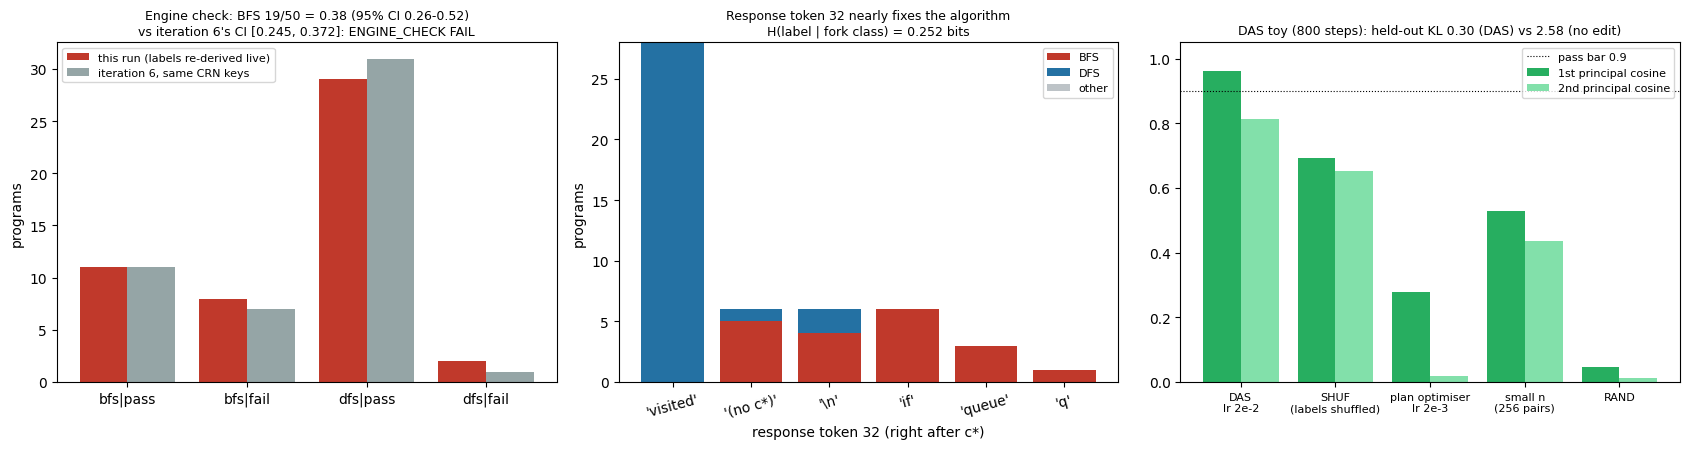

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

# (1) engine check: this run (live labels) vs iteration 6 on the same CRN slots
cur = Counter(f"{p['label']}|{'pass' if p['passed'] else 'fail'}" for p in eng["per_slot"])
old = Counter(f"{p['iter6_label']}|{'pass' if p['iter6_passed'] else 'fail'}" for p in eng["per_slot"])
cats = ["bfs|pass", "bfs|fail", "dfs|pass", "dfs|fail"]
cats += sorted((set(cur) | set(old)) - set(cats))
x = np.arange(len(cats))
axes[0].bar(x - 0.2, [cur[c] for c in cats], 0.4, color="#c0392b", label="this run (labels re-derived live)")
axes[0].bar(x + 0.2, [old[c] for c in cats], 0.4, color="#95a5a6", label="iteration 6, same CRN keys")
axes[0].set_xticks(x, cats)
axes[0].set_ylabel("programs")
axes[0].legend(fontsize=8)
lo, hi = eng["wilson95"]
axes[0].set_title(f"Engine check: BFS {eng['bfs']}/{eng['n']} = {eng['share']:.2f} (95% CI {lo:.2f}-{hi:.2f})\n"
                  f"vs iteration 6's CI {eng['iter6_ci95_for_61_of_200']}: ENGINE_CHECK "
                  f"{'PASS' if eng['pass'] else 'FAIL'}", fontsize=9)

# (2) response token 32 -> algorithm
toks = [tk for tk, _ in Counter(x["token"] for x in fork_rows).most_common()]
nb = np.array([sum(x["token"] == tk and x["label"] == "bfs" for x in fork_rows) for tk in toks])
nd = np.array([sum(x["token"] == tk and x["label"] == "dfs" for x in fork_rows) for tk in toks])
no = np.array([sum(x["token"] == tk and x["label"] not in ("bfs", "dfs") for x in fork_rows) for tk in toks])
xb = np.arange(len(toks))
axes[1].bar(xb, nb, color="#c0392b", label="BFS")
axes[1].bar(xb, nd, bottom=nb, color="#2471a3", label="DFS")
axes[1].bar(xb, no, bottom=nb + nd, color="#bdc3c7", label="other")
axes[1].set_xticks(xb, [repr(tk) for tk in toks], rotation=15)
axes[1].set_xlabel("response token 32 (right after c*)")
axes[1].set_ylabel("programs")
axes[1].legend(fontsize=8)
axes[1].set_title(f"Response token 32 nearly fixes the algorithm\nH(label | fork class) = {H_engine:.3f} bits", fontsize=9)

# (3) DAS toy: principal cosines between the planted Q and each learned R
toy_runs = [("DAS\nlr 2e-2", lt["das"]["principal_cosines"]), ("SHUF\n(labels shuffled)", lt["shuf"]["principal_cosines"]),
            ("plan optimiser\nlr 2e-3", lt["plan_optimiser_lr2e-3"]["principal_cosines"]),
            ("small n\n(256 pairs)", lt["small_n_overfit"]["principal_cosines"]), ("RAND", lt["rand_principal_cosines"])]
xt = np.arange(len(toy_runs))
axes[2].bar(xt - 0.2, [c[0] for _, c in toy_runs], 0.4, color="#27ae60", label="1st principal cosine")
axes[2].bar(xt + 0.2, [c[1] for _, c in toy_runs], 0.4, color="#82e0aa", label="2nd principal cosine")
axes[2].axhline(0.9, color="black", ls=":", lw=0.8, label="pass bar 0.9")
axes[2].set_xticks(xt, [n for n, _ in toy_runs], fontsize=8)
axes[2].set_ylim(0, 1.05)
axes[2].legend(fontsize=8)
axes[2].set_title(f"DAS toy ({TOY_STEPS} steps): held-out KL {lt['das']['heldout_kl']:.2f} (DAS) vs "
                  f"{lt['das']['heldout_kl_no_edit']:.2f} (no edit)", fontsize=9)
plt.tight_layout()
plt.show()

### Figures of the recorded GPU-stage results (the artifact's F6, F5 and F4, redrawn)

1. **G3: is temperature the creativity knob?** The predictions were committed (#1) from teacher-forced logits before any temperature sample: pred(T) = P(c*) · Σ_t softmax(z/T)_t · P(BFS | t) + (1 − P(c*)) · π_other. They match every observed share within its Wilson interval. Temperature only moves mass across the one fork the model already has; it adds no new algorithm. Top-k 10 changes nothing, program for program.
2. **G2: a dose dial.** Editing the fork state at layer 17 inside the rank-4 DAS subspace, toward the BFS class mean by λ, raises *correct* BFS programs from 11 to 42 of 50 and keeps the pass rate. The same teacher-forced push along the difference-in-means (DiM) direction flips the algorithm but breaks the programs. Dosed DAS (42) beats asking for BFS in the prompt (35).
3. **F4: geometry in actual activation coordinates.** The fork states (layer 17, position p_f) of the 120 neutral twin variants (coloured by their fork margin y_v) and of the 40 forced-BFS/DFS prompts, projected onto the first two trained DAS directions. The dashed line is the DAS dose path from the twin centroid to the forced-BFS centroid; the orange arrow is the DiM direction. The 2-D coordinates were computed with `fig_geometry`'s own projection from the cached 2560-d states (`cache/states/`, 14-42 MB, not shipped).

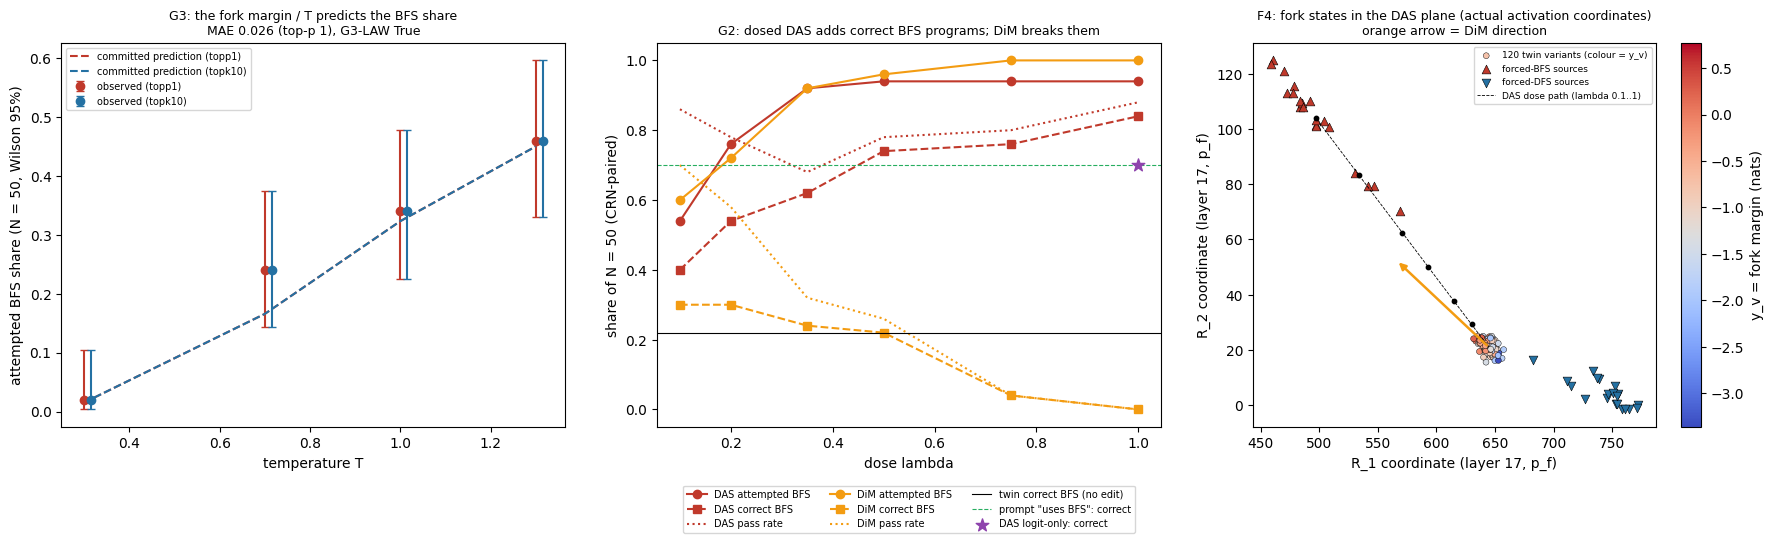

In [22]:
from cfg import DOSES, TEMPS

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))

# (1) G3 (src/analysis7.py fig_temperature): committed prediction vs observed attempted-BFS share
c = REC["g3_sweep"]["cells"]
for smp, col in (("topp1", "#c0392b"), ("topk10", "#2471a3")):
    xs = [T for T in TEMPS if f"T{T}|{smp}" in c]
    obs = np.array([c[f"T{T}|{smp}"]["attempted_share"] for T in xs])
    lo = np.array([c[f"T{T}|{smp}"]["ci95"][0] for T in xs])
    hi = np.array([c[f"T{T}|{smp}"]["ci95"][1] for T in xs])
    pr = [c[f"T{T}|{smp}"]["pred_primary"] for T in xs]
    axes[0].errorbar(np.array(xs) + (0.015 if smp == "topk10" else 0), obs, yerr=[obs - lo, hi - obs], fmt="o",
                     color=col, capsize=3, label=f"observed ({smp})")
    axes[0].plot(xs, pr, "--", color=col, label=f"committed prediction ({smp})")
axes[0].set_xlabel("temperature T")
axes[0].set_ylabel("attempted BFS share (N = 50, Wilson 95%)")
axes[0].legend(fontsize=7)
axes[0].set_title(f"G3: the fork margin / T predicts the BFS share\nMAE {REC['g3_sweep']['MAE_topp1']:.3f} "
                  f"(top-p 1), G3-LAW {REC['g3_sweep']['G3_LAW']}", fontsize=9)

# (2) G2 dose toward BFS (src/analysis7.py fig_dose, left panel)
d = REC["g2_dose"]["cells"]
for meth, col in (("DAS", "#c0392b"), ("DiM", "#f39c12")):
    xs = [lam for lam in DOSES if f"{meth}|bfs|{lam}" in d]
    axes[1].plot(xs, [d[f"{meth}|bfs|{lam}"]["attempted_share"] for lam in xs], "o-", color=col, label=f"{meth} attempted BFS")
    axes[1].plot(xs, [d[f"{meth}|bfs|{lam}"]["correct_share"] for lam in xs], "s--", color=col, label=f"{meth} correct BFS")
    axes[1].plot(xs, [d[f"{meth}|bfs|{lam}"]["pass_rate"] for lam in xs], ":", color=col, label=f"{meth} pass rate")
axes[1].axhline(d["twin"]["correct_share"], color="black", lw=0.8, label="twin correct BFS (no edit)")
axes[1].axhline(d["forced_bfs_F5"]["correct_share"], color="#27ae60", lw=0.8, ls="--", label='prompt "uses BFS": correct')
axes[1].scatter([1.0], [d["DAS-L|bfs|1.0"]["correct_share"]], marker="*", s=90, color="#8e44ad", zorder=4,
                label="DAS logit-only: correct")
axes[1].set_xlabel("dose lambda")
axes[1].set_ylabel("share of N = 50 (CRN-paired)")
axes[1].legend(fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.14))
axes[1].set_title("G2: dosed DAS adds correct BFS programs; DiM breaks them", fontsize=9)

# (3) F4 geometry (src/analysis7.py fig_geometry) from the shipped 2-D projections
geo = REC["g2_geometry"]
pv = np.array([v["xy"] for v in geo["variants"]])
yv = np.array([v["y"] for v in geo["variants"]])
ps = np.array([s["xy"] for s in geo["sources"]])
mb = np.array([s["mode"] == "bfs" for s in geo["sources"]])
ud = np.array(geo["dim_xy"])
ax = axes[2]
sc = ax.scatter(pv[:, 0], pv[:, 1], c=yv, cmap="coolwarm", s=18, edgecolor="black", lw=0.3,
                label="120 twin variants (colour = y_v)")
plt.colorbar(sc, ax=ax, label="y_v = fork margin (nats)")
ax.scatter(ps[mb, 0], ps[mb, 1], marker="^", s=40, color="#c0392b", edgecolor="black", lw=0.4, label="forced-BFS sources")
ax.scatter(ps[~mb, 0], ps[~mb, 1], marker="v", s=40, color="#2471a3", edgecolor="black", lw=0.4, label="forced-DFS sources")
c0 = pv.mean(0)
tb = ps[mb].mean(0)
scale = 0.5 * float(np.linalg.norm(tb - c0)) / max(float(np.linalg.norm(ud)), 1e-9)
ax.annotate("", xy=(c0[0] + ud[0] * scale, c0[1] + ud[1] * scale), xytext=(c0[0], c0[1]),
            arrowprops=dict(arrowstyle="-|>", color="#f39c12", lw=1.8))
for lam in DOSES:
    q = c0 + lam * (tb - c0)
    ax.scatter([q[0]], [q[1]], s=10, color="black")
ax.plot([c0[0], tb[0]], [c0[1], tb[1]], color="black", lw=0.6, ls="--", label="DAS dose path (lambda 0.1..1)")
ax.set_xlabel(f"R_1 coordinate (layer {geo['L_star']}, p_f)")
ax.set_ylabel(f"R_2 coordinate (layer {geo['L_star']}, p_f)")
ax.legend(fontsize=6.5, loc="best")
ax.set_title("F4: fork states in the DAS plane (actual activation coordinates)\norange arrow = DiM direction", fontsize=9)
plt.tight_layout()
plt.show()

## Takeaways

- **Does the model always design BFS?** No. Given the same twin prompt and iteration 6's seeds, Gemma-3-4B-it mostly writes **DFS** (31 of 50) and BFS 19 times; 40 of 50 programs pass the hidden tests. The frozen labeller re-derives every one of these labels live in this notebook. The choice is made at a single token, response index 32: ` visited` leads to DFS, while a blank line, `if`, `queue` or `q` lead to BFS.
- **Is temperature the creativity knob?** Not in this case study. The recorded G3 sweep shows temperature only re-weights that one fork, at the rate the fork logits divided by T predict, and the predictions were committed before sampling. Top-k 10 changes nothing. Across all arms, none of the 2,325 correct programs was labelled 'other' (no novel algorithm; rule-of-three bound 0.0013).
- **Can we influence it from inside?** Yes, at the fork. A rank-4 DAS subspace at layer 17, dosed toward the BFS class mean, raises correct BFS programs from 11 to 42 of 50 and keeps them passing. That beats the explicit "uses BFS" prompt (35). A difference-in-means push of the same teacher-forced size flips the algorithm but breaks the programs. G1 path patching finds the components that compute the fork margin: MLPs at the condition sentence, plus a fork-position stack (MLP L21/L22, head L22.H5, MLP L25/L26).
- **Scope.** One model, one task, one natural fork: a case study, not a general circuit claim. The seed-to-seed identifiability of the DAS subspace is weak (principal cosine about 0.5), and "one-dimensional" is not licensed by the committed rule.

**To run more.** The config cell holds the artifact's original CPU-side settings. Re-running the GPU stages (sampling, path patching, DAS training, dose sweeps) needs the full artifact repository, a 16 GB GPU and access to the gated `google/gemma-3-4b-it`; the commands are in the dispatch section above.